In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#model 
from sklearn.linear_model import LogisticRegression
#train_test_split 
from sklearn.model_selection import train_test_split
#data scaling
from sklearn.preprocessing import StandardScaler
#metrics
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

In [7]:
df= pd.read_csv('heart_disease_prediction_cleaned.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


HeartDisease
1    55.288986
0    44.711014
Name: proportion, dtype: float64


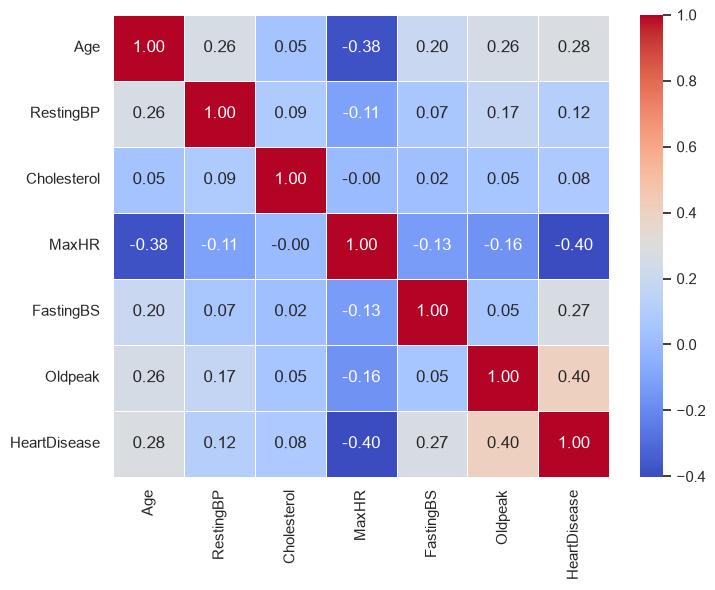

In [8]:
sns.set_theme(style='whitegrid')
print(df['HeartDisease'].value_counts(normalize=True)*100)
plt.figure(figsize= (8,6))
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'FastingBS', 'Oldpeak','HeartDisease']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True , cmap = 'coolwarm', fmt=".2f", linewidths=0.5)
plt.show()

- OLD PEAK (r=0.40) shows moderate positive correlation whereas MaxHR (r=-0.40) shows moderate negative correlation with HeartDisease. 
- RestingBP and Cholesterol show negligible correlation with HeartDisease.
- Age and FastingBS show weak-to-moderate positive correlation with HeartDisease.

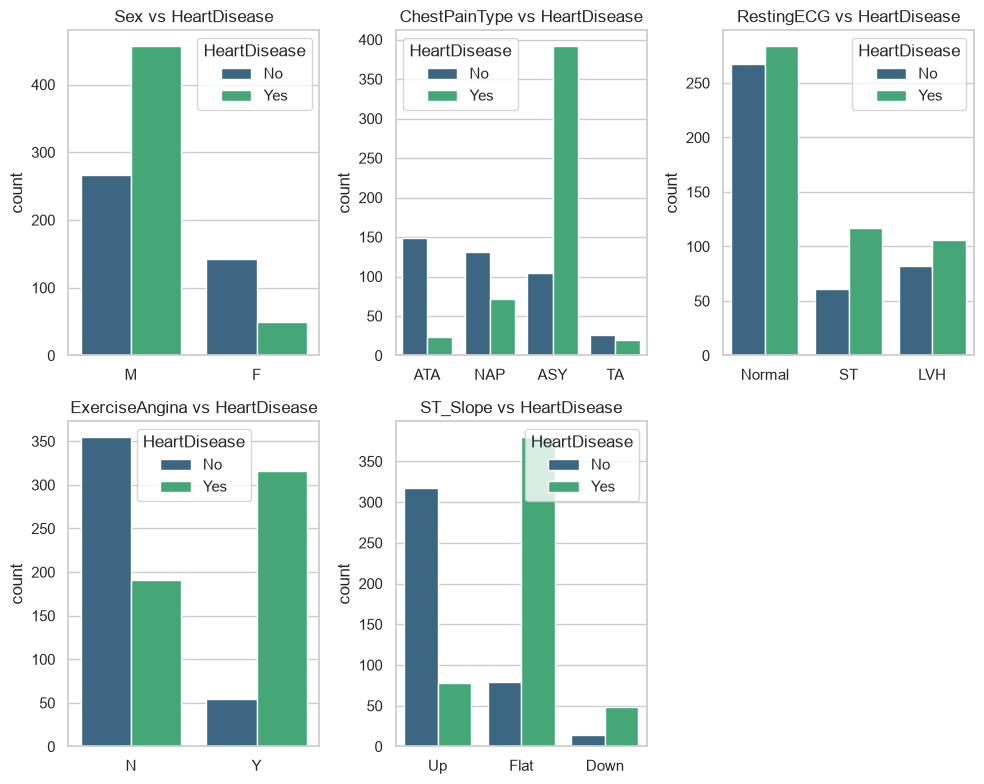

In [9]:
categorical_cols = ['Sex','ChestPainType','RestingECG','ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(nrows = 2, ncols=3, figsize=(10,8))
axes=axes.flatten()

for i,col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, hue='HeartDisease', ax=axes[i], palette='viridis')
    axes[i].set_title(f'{col} vs HeartDisease')
    axes[i].set_xlabel('')
    axes[i].legend(title = 'HeartDisease', labels = ['No', 'Yes'])

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

- Heart Disease is more common among Male whereas less among female.
- Asymptomatic (ASY) chest pain is overwhelmingly associated with heart disease (Yes bar towers over No), making it one of the strongest categorical risk indicators. Conversely, Atypical Angina (ATA) and Non-Anginal Pain (NAP) have higher counts of healthy patients.
- Patients with exercise-induced angina (Y) heavily skew toward having heart disease, whereas those without (N) mostly do not.
- Patients with ST_Slope Up heavily skew toward having heart disease.
- Resting ECG show fairly balanced distribution across categories, although ST and LVH abnormalities have slightly higher proportion of heart disease cases. 


Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')